# AI Programming Foundations — Data Workflow

**Student:** Hershal Rooplall  
**Dataset:** World Bank *A Cross-Country Database of Fiscal Space* (`WB_CCDFS_WIDEF.csv`)  
**Source:** `gs://cce-wb-data360/cce-world-bank-data/raw-export/A Cross-Country Database of Fiscal Space/` (CC BY 3.0 IGO)

This notebook builds a reproducible tabular workflow: load, clean, explore, and visualize fiscal-space indicators across economies. No machine learning models are trained. The goal is a professional foundation for later ML and industry-synthesis work.


## Setup


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
DATA_PATH = Path("data/WB_CCDFS_WIDEF.csv")
assert DATA_PATH.exists(), f"Missing dataset at {DATA_PATH}"
print("Libraries imported.")


Libraries imported.


## Ingestion


In [2]:
df_wide = pd.read_csv(DATA_PATH)
print(f"Wide shape: {df_wide.shape}")
df_wide.head()


Wide shape: (3375, 49)


,FREQ,FREQ_LABEL,REF_AREA,REF_AREA_LABEL,INDICATOR,INDICATOR_LABEL,UNIT_MEASURE,UNIT_MEASURE_LABEL,DATABASE_ID,DATABASE_ID_LABEL,...,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
0,A,Annual,ABW,Aruba,WB_CCDFS_DEBTDUEY,Central government debt maturing in 12 months ...,PT,Percentage,WB_CCDFS,A Cross-Country Database of Fiscal Space,...,2.796921,0.333214,1.083226,1.075603,1.678525,1.398046,1.348645,3.282532,2.707058,2.369535
1,A,Annual,ABW,Aruba,WB_CCDFS_FBMA,"Fiscal balance, % of 10-year moving average GDP",PT,Percentage,WB_CCDFS,A Cross-Country Database of Fiscal Space,...,-6.446430,-7.966341,-1.634916,-1.593364,-2.891918,-3.079565,-0.285148,-14.299284,-9.635033,-0.541551
2,A,Annual,ABW,Aruba,WB_CCDFS_FBY,"Fiscal balance, % of GDP",PT,Percentage,WB_CCDFS,A Cross-Country Database of Fiscal Space,...,-6.048000,-7.459000,-1.475000,-1.455000,-2.587000,-2.641000,-0.243000,-16.230000,-9.161000,-0.465000
3,A,Annual,ABW,Aruba,WB_CCDFS_GGDMA,"General government gross debt, % of 10-year mo...",PT,Percentage,WB_CCDFS,A Cross-Country Database of Fiscal Space,...,74.645564,83.005679,82.219094,82.555968,84.762163,85.483871,83.377121,98.975189,107.084439,104.945632
4,A,Annual,ABW,Aruba,WB_CCDFS_GGDY,"General government gross debt, % of GDP",PT,Percentage,WB_CCDFS,A Cross-Country Database of Fiscal Space,...,70.032000,77.709000,74.177000,75.387000,75.825000,73.310000,71.053000,112.339000,101.816000,90.111000


In [3]:
print("Columns (first 20):", list(df_wide.columns[:20]))
print("dtypes sample:")
print(df_wide.dtypes.head(15))
year_cols = [c for c in df_wide.columns if str(c).isdigit()]
print(f"Year columns: {len(year_cols)} from {min(year_cols)} to {max(year_cols)}")
print("Obvious data-quality notes: wide format with many NaNs for sparse indicators/years; country coverage varies by indicator.")


Columns (first 20): ['FREQ', 'FREQ_LABEL', 'REF_AREA', 'REF_AREA_LABEL', 'INDICATOR', 'INDICATOR_LABEL', 'UNIT_MEASURE', 'UNIT_MEASURE_LABEL', 'DATABASE_ID', 'DATABASE_ID_LABEL', 'UNIT_MULT', 'UNIT_MULT_LABEL', 'OBS_STATUS', 'OBS_STATUS_LABEL', 'OBS_CONF', 'OBS_CONF_LABEL', '1990', '1991', '1992', '1993']
dtypes sample:
FREQ                    str
FREQ_LABEL              str
REF_AREA                str
REF_AREA_LABEL          str
INDICATOR               str
INDICATOR_LABEL         str
UNIT_MEASURE            str
UNIT_MEASURE_LABEL      str
DATABASE_ID             str
DATABASE_ID_LABEL       str
UNIT_MULT             int64
UNIT_MULT_LABEL         str
OBS_STATUS              str
OBS_STATUS_LABEL        str
OBS_CONF                str
dtype: object
Year columns: 33 from 1990 to 2022
Obvious data-quality notes: wide format with many NaNs for sparse indicators/years; country coverage varies by indicator.


## Cleaning


In [4]:
def wide_to_long(df: pd.DataFrame) -> pd.DataFrame:
    """Reshape fiscal-space wide table to long country-indicator-year observations.

    Melts year columns into TIME_PERIOD and OBS_VALUE while preserving
    identifier and label columns required for analysis.
    """
    id_vars = [c for c in df.columns if not str(c).isdigit()]
    year_cols = [c for c in df.columns if str(c).isdigit()]
    long_df = df.melt(id_vars=id_vars, value_vars=year_cols,
                      var_name="TIME_PERIOD", value_name="OBS_VALUE")
    long_df["TIME_PERIOD"] = long_df["TIME_PERIOD"].astype(int)
    return long_df


def drop_empty_observations(df: pd.DataFrame) -> pd.DataFrame:
    """Remove rows with missing OBS_VALUE after the wide-to-long reshape.

    Empty cells in the wide export represent non-reported years rather than
    zeros; dropping them avoids treating missingness as a numeric value.
    """
    before = len(df)
    cleaned = df.dropna(subset=["OBS_VALUE"]).copy()
    cleaned["OBS_VALUE"] = pd.to_numeric(cleaned["OBS_VALUE"], errors="coerce")
    cleaned = cleaned.dropna(subset=["OBS_VALUE"])
    print(f"Dropped {before - len(cleaned):,} empty/invalid observations; kept {len(cleaned):,}.")
    return cleaned


df_long = wide_to_long(df_wide)
df = drop_empty_observations(df_long)
df.head()


Dropped 24,960 empty/invalid observations; kept 86,415.


,FREQ,FREQ_LABEL,REF_AREA,REF_AREA_LABEL,INDICATOR,INDICATOR_LABEL,UNIT_MEASURE,UNIT_MEASURE_LABEL,DATABASE_ID,DATABASE_ID_LABEL,UNIT_MULT,UNIT_MULT_LABEL,OBS_STATUS,OBS_STATUS_LABEL,OBS_CONF,OBS_CONF_LABEL,TIME_PERIOD,OBS_VALUE
6,A,Annual,ABW,Aruba,WB_CCDFS_PSCY,"Domestic credit to private sector, % of GDP",PT,Percentage,WB_CCDFS,A Cross-Country Database of Fiscal Space,0,Units,A,Normal value,PU,Public,1990,44.488678
26,A,Annual,AGO,Angola,WB_CCDFS_CONCGGD,"Concessional external debt stocks, % of extern...",PT,Percentage,WB_CCDFS,A Cross-Country Database of Fiscal Space,0,Units,A,Normal value,PU,Public,1990,0.765696
35,A,Annual,AGO,Angola,WB_CCDFS_PRDEBTY,"Private external debt stocks, % of GDP",PT,Percentage,WB_CCDFS,A Cross-Country Database of Fiscal Space,0,Units,A,Normal value,PU,Public,1990,0.038904
38,A,Annual,AGO,Angola,WB_CCDFS_STDEBTALL,"Short-term external debt stocks, % of total",PT,Percentage,WB_CCDFS,A Cross-Country Database of Fiscal Space,0,Units,A,Normal value,PU,Public,1990,11.504284
42,A,Annual,AGO,Angola,WB_CCDFS_XTDEBTY,"Total external debt stocks, % of GDP",PT,Percentage,WB_CCDFS,A Cross-Country Database of Fiscal Space,0,Units,A,Normal value,PU,Public,1990,68.346957


## Exploratory Analysis


In [5]:
def explore_fiscal_space(df: pd.DataFrame) -> dict:
    """Summarize fiscal-space coverage, distributions, and indicator sparsity.

    Returns a dictionary of summary tables used for interpretation and plots.
    """
    summary = {
        "n_rows": len(df),
        "n_countries": df["REF_AREA"].nunique(),
        "n_indicators": df["INDICATOR"].nunique(),
        "year_range": (int(df["TIME_PERIOD"].min()), int(df["TIME_PERIOD"].max())),
        "describe": df["OBS_VALUE"].describe(),
        "top_indicators": df["INDICATOR_LABEL"].value_counts().head(10),
        "coverage_by_indicator": (
            df.groupby("INDICATOR_LABEL")["REF_AREA"]
              .nunique()
              .sort_values()
              .head(10)
        ),
    }
    print(f"Rows: {summary['n_rows']:,}")
    print(f"Countries: {summary['n_countries']}")
    print(f"Indicators: {summary['n_indicators']}")
    print(f"Years: {summary['year_range'][0]}–{summary['year_range'][1]}")
    print("\nOBS_VALUE describe:")
    print(summary["describe"])
    print("\nFewest-country indicators (coverage risk):")
    print(summary["coverage_by_indicator"])
    return summary

eda = explore_fiscal_space(df)


Rows: 86,415
Countries: 202
Indicators: 23
Years: 1990–2022

OBS_VALUE describe:
count    8.641500e+04
mean     7.441540e+02
std      1.592031e+04
min     -1.376827e+04
25%      4.495039e-01
50%      1.835276e+01
75%      7.802105e+01
max      1.411828e+06
Name: OBS_VALUE, dtype: float64

Fewest-country indicators (coverage risk):
INDICATOR_LABEL
External debt in foreign currency, % of total                          44
Debt securities held by nonresidents, % of total                       49
General government debt in foreign currency, % of total                56
General government debt held by nonresidents, % of total               78
Sovereign debt average maturity, years                                 96
Concessional external debt stocks, % of external public debt          120
Cyclically-adjusted balance, % of potential GDP                       135
Central government debt maturing in 12 months or less, % of GDP       136
Foreign currency long-term sovereign debt ratings, index fr

## Visualizations


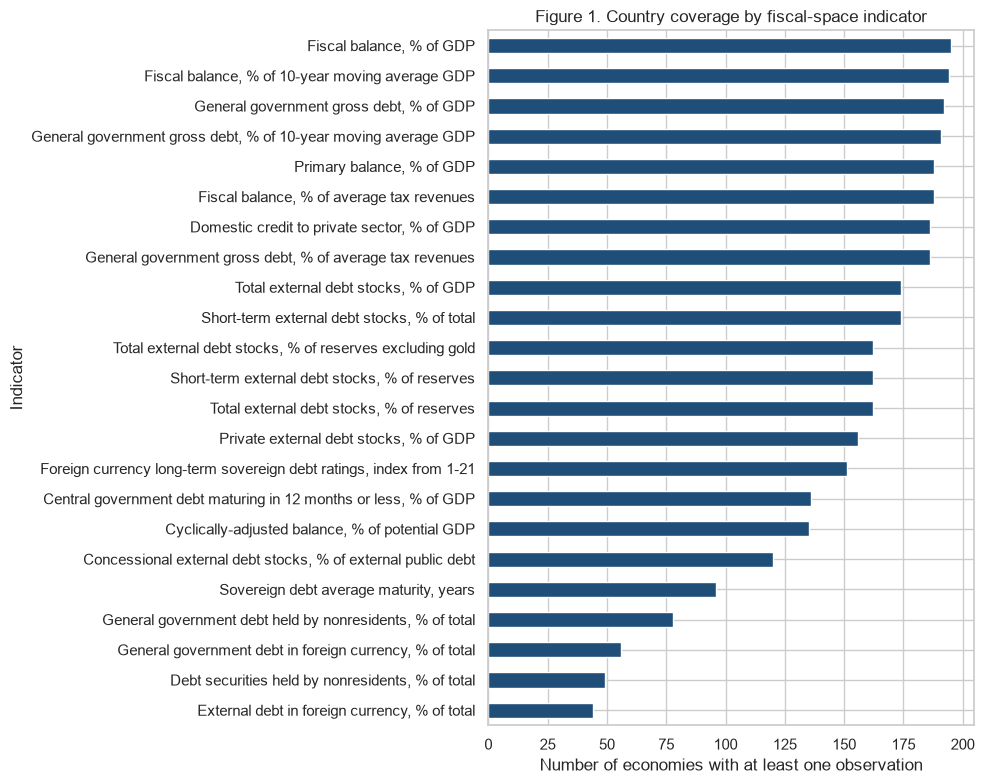

In [6]:
# Figure 1 — Missingness / coverage by indicator (countries reporting at least once)
coverage = (
    df.groupby("INDICATOR_LABEL")["REF_AREA"].nunique()
      .sort_values(ascending=True)
)
fig, ax = plt.subplots(figsize=(10, 8))
coverage.plot(kind="barh", ax=ax, color="#1f4e79")
ax.set_title("Figure 1. Country coverage by fiscal-space indicator")
ax.set_xlabel("Number of economies with at least one observation")
ax.set_ylabel("Indicator")
plt.tight_layout()
plt.show()


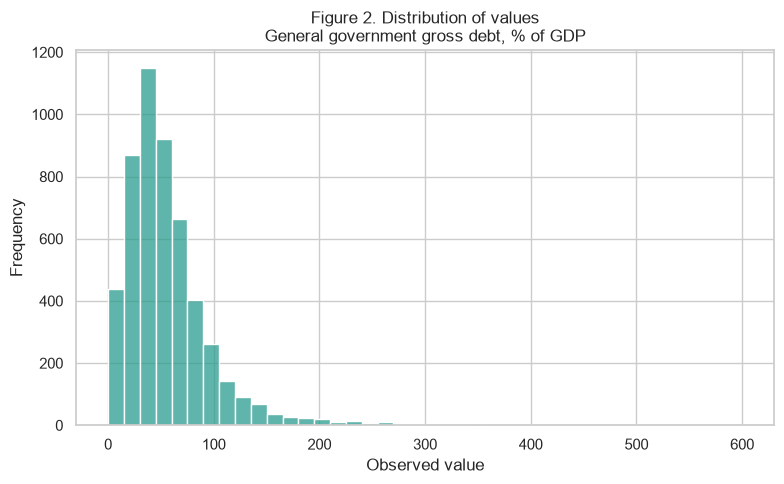

In [7]:
# Figure 2 — Distribution of a core debt-sustainability style indicator if present
# Prefer labels containing 'debt' and '% of GDP'
debt_mask = df["INDICATOR_LABEL"].str.contains("debt", case=False, na=False) &             df["INDICATOR_LABEL"].str.contains("% of GDP|GDP", case=False, na=False)
debt_df = df[debt_mask].copy()
if debt_df.empty:
    # fallback: most common indicator
    top_ind = df["INDICATOR_LABEL"].value_counts().index[0]
    debt_df = df[df["INDICATOR_LABEL"] == top_ind].copy()
    title_ind = top_ind
else:
    title_ind = debt_df["INDICATOR_LABEL"].value_counts().index[0]
    debt_df = debt_df[debt_df["INDICATOR_LABEL"] == title_ind]

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(debt_df["OBS_VALUE"], bins=40, ax=ax, color="#2a9d8f")
ax.set_title(f"Figure 2. Distribution of values\n{title_ind[:90]}")
ax.set_xlabel("Observed value")
ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()


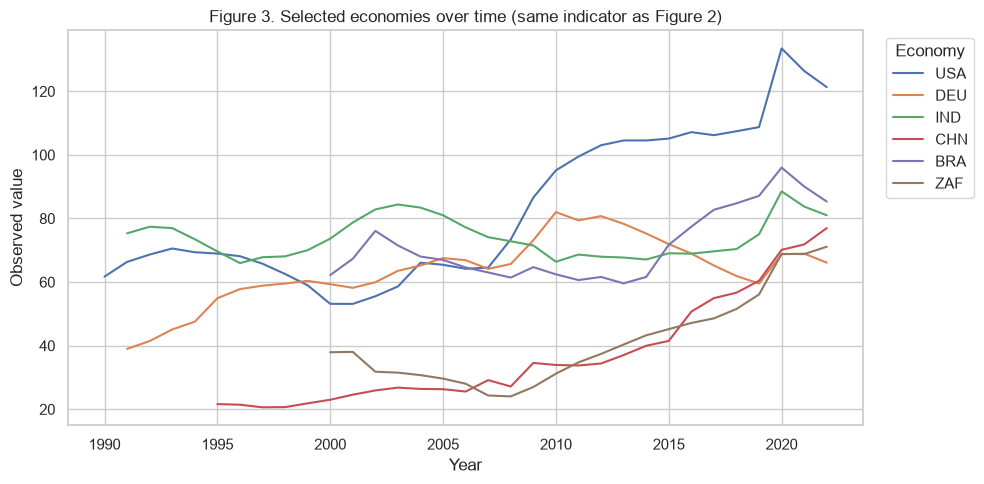

In [8]:
# Figure 3 — Time path for a few large economies on one indicator
focus_countries = [c for c in ["USA", "DEU", "ZAF", "BRA", "IND", "CHN"] if c in set(df["REF_AREA"])]
plot_df = debt_df[debt_df["REF_AREA"].isin(focus_countries)].copy()
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=plot_df, x="TIME_PERIOD", y="OBS_VALUE", hue="REF_AREA", ax=ax)
ax.set_title("Figure 3. Selected economies over time (same indicator as Figure 2)")
ax.set_xlabel("Year")
ax.set_ylabel("Observed value")
ax.legend(title="Economy", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## Summary and Interpretation

The fiscal-space wide extract reshapes cleanly into a long panel of country–indicator–year observations. Coverage is uneven: some indicators are reported for nearly all economies, while market-access and certain balance-sheet measures are sparse—consistent with the database construction described by Kose et al. (2022), where market-access concepts require traded debt instruments that many low-income economies do not issue.

Patterns in the visualizations show that country coverage itself is an analytic feature, not only a data defect. Treating sparse indicators as if they were globally representative would bias comparisons toward economies with deeper markets. Time paths for selected economies illustrate level differences and crisis-period movements, but cross-country levels should not be compared without reading each indicator’s unit and definition.

**Limitations and assumptions:** years with blank cells were dropped rather than imputed; income-group comparisons in the written report use external World Bank group labels joined where available, or REF_AREA panels alone when a mapping file is absent; no causal claims are made. Surprising elements include how early the year axis starts for some series and how many indicators remain empty for small economies even in recent years.

This workflow stops at reproducible EDA. It does not train predictive models.
